# AI readiness scorecard

How usable is the OSDR metadata (Tier 1 fields) for search and ML? Compares the raw data with the cleaned data from `data_cleanup.ipynb`.

In [1]:
import pandas as pd

raw = pd.read_parquet("../data/clean/studies_subset_t1.parquet")
df = pd.read_parquet("../data/clean/studies_subset_t1_cleaned.parquet")
print(raw.shape, df.shape)

(577, 13) (576, 31)


## Completeness

In [2]:
# share of missing values per column (empty or "Not Applicable")
placeholder = raw.apply(lambda col: col.astype(str).str.strip().str.lower().isin(["not applicable", "n/a", ""]))
missing = raw.isna() | placeholder
missing.mean().sort_values(ascending=False).round(3)

Mission.Name                    0.506
Flight Program                  0.478
Space Program                   0.331
Material Type                   0.149
organism                        0.007
Project Type                    0.002
Study Assay Technology Type     0.002
Study Assay Measurement Type    0.002
Study Description               0.000
Study Title                     0.000
Accession                       0.000
Study Factor Name               0.000
Study Public Release Date       0.000
dtype: float64

In [3]:
# flight platform is only expected for spaceflight studies
spaceflight = df[df["project_type"] == "Spaceflight"]
print("spaceflight studies without flight platform:", (spaceflight["n_flight_platforms"] == 0).sum(), "of", len(spaceflight))

# how many values were added by hand or inferred
for col in ["organism_source", "space_program_source", "flight_program_source", "project_type_source"]:
    print(col, (df[col] != "OSDR metadata").sum())

spaceflight studies without flight platform: 10 of 322
organism_source 4
space_program_source 11
flight_program_source 24
project_type_source 4


## Consistency

In [4]:
# number of different raw values vs after cleaning
print("Project Type:", raw["Project Type"].nunique(), "->", df["project_type"].nunique())
print("Flight Program:", raw["Flight Program"].nunique(), "->", df["flight_platforms"].explode().nunique())
print("Space Program:", raw["Space Program"].nunique(), "->", df["space_agencies"].explode().nunique())
print("Material Type:", raw["Material Type"].nunique(), "->", df["material_types"].explode().nunique())

Project Type: 11 -> 5
Flight Program: 30 -> 10
Space Program: 38 -> 12
Material Type: 200 -> 183


In [5]:
# all raw values that ended up as just ISS
iss = df[df["flight_platforms"].apply(lambda x: list(x) == ["ISS"])]
iss["Flight Program"].value_counts()

Flight Program
International Space Station (ISS)                                             234
Internation Space Station (ISS)                                                10
Rodent Research (RR)                                                            5
ISS                                                                             4
International Space Station                                                     2
ISS National Laboratory                                                         2
International Space Station, NASA Biological and Physical Sciences Program      1
International space station (ISS)                                               1
International Space Staion (ISS)                                                1
Name: count, dtype: int64

In [6]:
# studies that have something in Space Program but no space agency after cleaning (only funders, vehicles etc.)
has_program = df["Space Program"].notna() & (df["space_program_source"] == "OSDR metadata")
print("only funders / vehicles:", (has_program & (df["n_space_agencies"] == 0)).sum())

only funders / vehicles: 8


## Validity

In [7]:
dates = raw["Study Public Release Date"].astype(float)
print("stored as:", raw["Study Public Release Date"].dtype)
print("dates that are 0 (1970):", (dates == 0).sum())

stored as: string
dates that are 0 (1970): 14


## Structure

In [8]:
# share of values with 2+ spaces in them = several values packed into one string
raw.apply(lambda col: col.astype(str).str.contains(r"\s{2,}").mean()).sort_values(ascending=False).head(8).round(3)

Study Factor Name               0.724
Study Assay Measurement Type    0.151
Study Assay Technology Type     0.151
Material Type                   0.083
organism                        0.059
Mission.Name                    0.035
Study Description               0.033
Study Title                     0.000
dtype: float64

## Uniqueness

In [9]:
print("duplicate accessions:", raw.loc[raw["Accession"].duplicated(), "Accession"].tolist())
print("studies with the same description as another study:", df["Study Description"].duplicated().sum())

duplicate accessions: ['OSD-729']
studies with the same description as another study: 45


## Text quality

median words per description: 192.5
under 20 words: 18


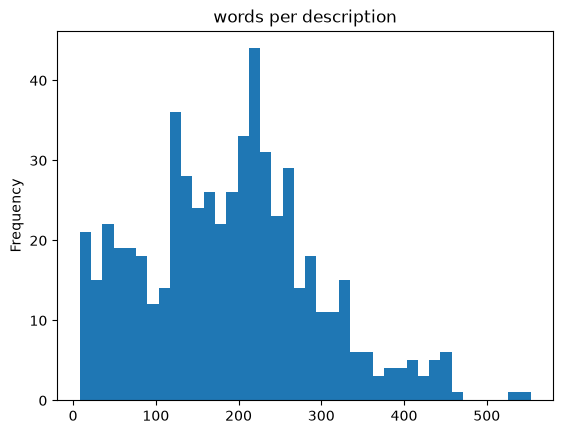

In [10]:
words = df["Study Description"].str.split().str.len()
print("median words per description:", words.median())
print("under 20 words:", (words < 20).sum())
words.plot.hist(bins=40, title="words per description");

## Scorecard

written by hand from the outputs above, also in `reports/readiness_scorecard.md`

| | Rating | Why | What would help |
|---|---|---|---|
| Completeness | ok | Material Type missing in 15% of studies. After cleaning only 10 of 322 spaceflight studies have no flight platform, but 4 organisms, 11 space programs and 24 flight platforms had to be added by hand or from mission names | required fields when submitting a study |
| Consistency | bad | ISS is written 9 different ways (typos like "Internation Space Station", program names). Project Type has 11 labels for 5 types. 8 studies only have funders or vehicles under Space Program | controlled vocabularies |
| Validity | ok | release dates are Unix timestamps stored as text, 14 of them are 0 (1970) | proper dates, empty instead of 0 |
| Structure | bad | lists are stored as text with 2+ spaces between values (72% of Study Factor Name). Space and Flight Program use , ; and "and", which also appear inside names | store lists as lists |
| Uniqueness | ok | 1 duplicate (OSD-729 is in the index twice with different release dates) | |
| Text quality | good | descriptions have a median of 192 words, only 18 are under 20 words | |

Overall: the titles and descriptions are good enough for semantic search as they are. The other fields work as filters after cleaning, but not for training models on them (Material Type still has 183 different values).